<a href="https://colab.research.google.com/github/LuzFlorez-C/proyecto-transporte-masivo/blob/main/ProyectoTransporteMasivo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
#importamos las librerias necesarias
import pandas as pd # Para manejo y estructuración de datos en tablas (dataframes)
import numpy as np # Para generación de número aleatorios y operaciones matemáticas

# Fijamo una semilla aleatoria para que los datos generados sean reproducibles
# (es decir, siempre se generen los mismos datos al correr el código)
np.random.seed(42)

# Definimos el número total de estaciones de nuestro sistema de transporte
n_estaciones = 100

# Creamos 3 tipos de comportamiento de estaciones:
# Grupo 0: Estaciones resisdenciales (mucha gente en la mañana, poca en la tarde)
# Grupo 1: Estaciones Centrales/Trabajo (poca gente en la mañana, mucha en la tarde)
# Grupo 2: Estaciones de Transbordo/Alta demanda (mucha gente todo el día)

# Generación aleatoria de pasajeros para la mañana y la tarde
manana_res = np.random.normal(loc=3500, scale=400, size=40)  # Residenciales
tarde_res = np.random.normal(loc=1200, scale=300, size=40)

manana_cen = np.random.normal(loc=1200, scale=300, size=35)  # Centrales
tarde_cen = np.random.normal(loc=3800, scale=400, size=35)

manana_tra = np.random.normal(loc=4000, scale=500, size=25)  # Transbordo
tarde_tra = np.random.normal(loc=4200, scale=500, size=25)

# Unimos lo datos generados para formar as columnas para formar las columnas finales
pasajeros_manana = np.concatenate([manana_res, manana_cen, manana_tra])
pasajeros_tarde = np.concatenate([tarde_res, tarde_cen, tarde_tra])

# Redondeamos a números enteros (ya que representan personas)
pasajeros_manana = np.round(pasajeros_manana).astype(int)
pasajeros_tarde = np.round(pasajeros_tarde).astype(int)

# Crear el DataFrame (tabla de datos) con pandas
df_transporte = pd.DataFrame({
    'id_estacion':[f'EST_{i+1:03d}' for i in range(n_estaciones)],
    'pasajeros_manana':pasajeros_manana,
    'pasajeros_tarde':pasajeros_tarde
})

# Guardamos los datos en un archivo CSV llamado 'estaciones_transporte.csv'
df_transporte.to_csv('estaciones_transporte.csv', index=False)

print(" Dataset creado y guardado exitosamente como 'estaciones_transporte.csv'")
df_transporte.head()

 Dataset creado y guardado exitosamente como 'estaciones_transporte.csv'


,id_estacion,pasajeros_manana,pasajeros_tarde
0,EST_001,3699,1422
1,EST_002,3445,1251
2,EST_003,3759,1165
3,EST_004,4109,1110
4,EST_005,3406,756


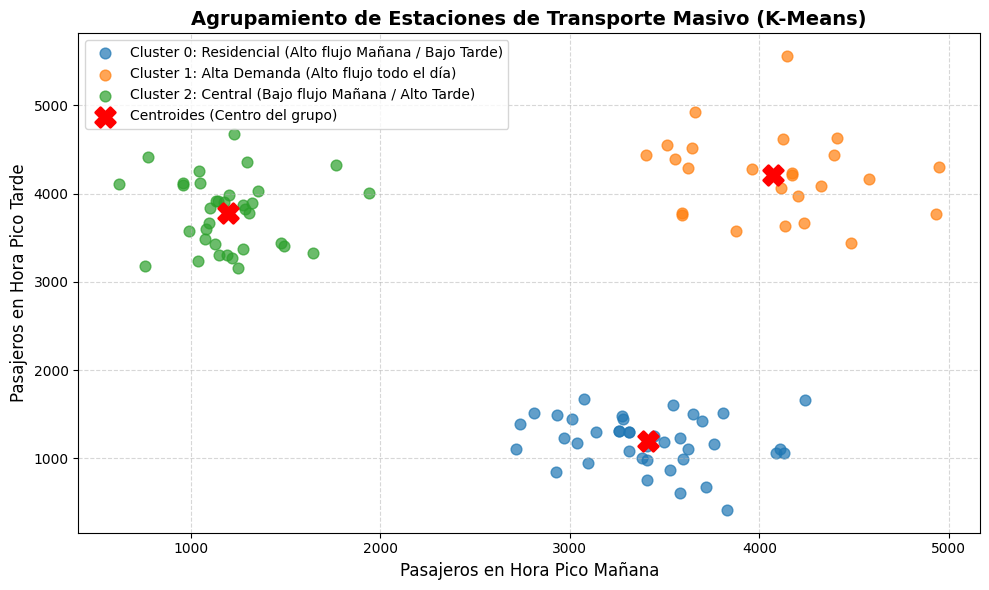

In [4]:
#================================================================
# MODELO DE APRENDIZAJE NO SUPERVISADO (K-MEANS) Y VISUALIZACIÓN
#================================================================

# Importamos las loibrerias necesarias
import pandas as pd
import matplotlib.pyplot as plt                         # Para crear los gráfico visuales
from sklearn.cluster import KMeans                      # Algoritmo de clustering K-Means
from sklearn.preprocessing import StandardScaler        # Para escalar/normalizar los datos

# 1. Cargar el dataset que generamos previamente
df = pd.read_csv('estaciones_transporte.csv')

# 2. seleccionar las variables o caracteristicas (features) para el modelo
# Usamos únicamente los datos númericos de flujos de pasajeros
X = df[['pasajeros_manana', 'pasajeros_tarde']]

# 3. Escalar los datos (Estandarización)
# Es una buena práctica en K-Means para que ninguna variable domine a la otra por la escala
scaler = StandardScaler()
X_escalado = scaler.fit_transform(X)

# 4. Crear e entrenar el modelo K-Means
# Definimos k=3 porque identificamos 3 patrones/grupos principales de estaciones
kmeans = KMeans(n_clusters=3, random_state=42)
df['cluster'] = kmeans.fit_predict(X_escalado) # Asignamos cada estación a un cluster (0, 1 o 2)

# 5. Obtener los centroides (puntos centrales de cada grupo) y revertir la escala para graficarlos
centroides_escalados =kmeans.cluster_centers_
centroides = scaler.inverse_transform(centroides_escalados)

#===============================================
# GENERACIÓN DE LA GRÁFICA CON MATPLOTLIB
#===============================================

# Definimos el tamaño de la figura (ancho, alto en pulgadas)
plt.figure(figsize=(10, 6))

# Graficamos los puntos de cada cluster con un color distinto
colores = ['#1f77b4', '#ff7f0e', '#2ca02c']
etiquetas = ['Cluster 0: Residencial (Alto flujo Mañana / Bajo Tarde)',
             'Cluster 1: Alta Demanda (Alto flujo todo el día)',
             'Cluster 2: Central (Bajo flujo Mañana / Alto Tarde)']

for i in range(3):
  # Filtramos las estaciones pertenecientes al cluster i
  datos_cluster = df[df['cluster'] == i]
  plt.scatter(
      datos_cluster['pasajeros_manana'],
      datos_cluster['pasajeros_tarde'],
      c=colores[i],
      label=etiquetas[i],
      alpha=0.7,
      s=60
  )

# Graficamos los centroides de cada grupo marcándolos con una 'X' roja grande
plt.scatter(
    centroides[:, 0],
    centroides[:, 1],
    c='red',
    marker='X',
    s=200,
    linewidths=2,
    label='Centroides (Centro del grupo)'
)

# Añadimos títulos y etiquetas claras a los ejes
plt.title('Agrupamiento de Estaciones de Transporte Masivo (K-Means)', fontsize=14, fontweight='bold')
plt.xlabel('Pasajeros en Hora Pico Mañana', fontsize=12)
plt.ylabel('Pasajeros en Hora Pico Tarde', fontsize=12)

# Añadimo una cuadrícula y la leyenda explicativa
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper left', fontsize=10)

#Mostramos el gráfico en pantalla
plt.tight_layout()
plt.show()

